In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error


In [6]:

data = {
    'Student': ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8'],
    'Practice_Hours': [1, 3, 5, 7, 9, 11, 13, 15],
    'Score': [20, 20, 40, 60, 60, 80, 80, 100]
}

df = pd.DataFrame(data)

X = df[['Practice_Hours']]
y = df['Score']

print(df)


  Student  Practice_Hours  Score
0      S1               1     20
1      S2               3     20
2      S3               5     40
3      S4               7     60
4      S5               9     60
5      S6              11     80
6      S7              13     80
7      S8              15    100


In [9]:

root_mean = y.mean()
root_mse = mean_squared_error(y, [root_mean] * len(y))

print("Root Mean =", root_mean)
print("Root MSE =", root_mse)


Root Mean = 57.5
Root MSE = 743.75


In [11]:

results = []

x_values = X['Practice_Hours'].values

thresholds = (x_values[:-1] + x_values[1:]) / 2

for t in thresholds:
    left = y[x_values <= t]
    right = y[x_values > t]

    left_mse = mean_squared_error(left, [left.mean()] * len(left))
    right_mse = mean_squared_error(right, [right.mean()] * len(right))

    weighted_mse = (
        len(left) * left_mse +
        len(right) * right_mse
    ) / len(y)

    results.append([
        t, left_mse, right_mse, weighted_mse
    ])

result_df = pd.DataFrame(
    results,
    columns=['Threshold', 'Left MSE', 'Right MSE', 'Weighted MSE']
)

print(result_df.round(2))


   Threshold  Left MSE  Right MSE  Weighted MSE
0        2.0      0.00     620.41        542.86
1        4.0      0.00     366.67        275.00
2        6.0     88.89     224.00        173.33
3        8.0    275.00     200.00        237.50
4       10.0    320.00      88.89        233.33
5       12.0    488.89     100.00        391.67
6       14.0    555.10       0.00        485.71


In [13]:

model = DecisionTreeRegressor(
    criterion='squared_error',
    max_depth=3,
    random_state=42
)

model.fit(X, y)

print("Decision Tree:")
print("Root and child thresholds:")
print(model.tree_.threshold)

print("\nTree Rules:")
from sklearn.tree import export_text

print(export_text(model, feature_names=['Practice_Hours']))


Decision Tree:
Root and child thresholds:
[ 6.  4. -2. -2. 10. -2. 14. -2. -2.]

Tree Rules:
|--- Practice_Hours <= 6.00
|   |--- Practice_Hours <= 4.00
|   |   |--- value: [20.00]
|   |--- Practice_Hours >  4.00
|   |   |--- value: [40.00]
|--- Practice_Hours >  6.00
|   |--- Practice_Hours <= 10.00
|   |   |--- value: [60.00]
|   |--- Practice_Hours >  10.00
|   |   |--- Practice_Hours <= 14.00
|   |   |   |--- value: [80.00]
|   |   |--- Practice_Hours >  14.00
|   |   |   |--- value: [100.00]



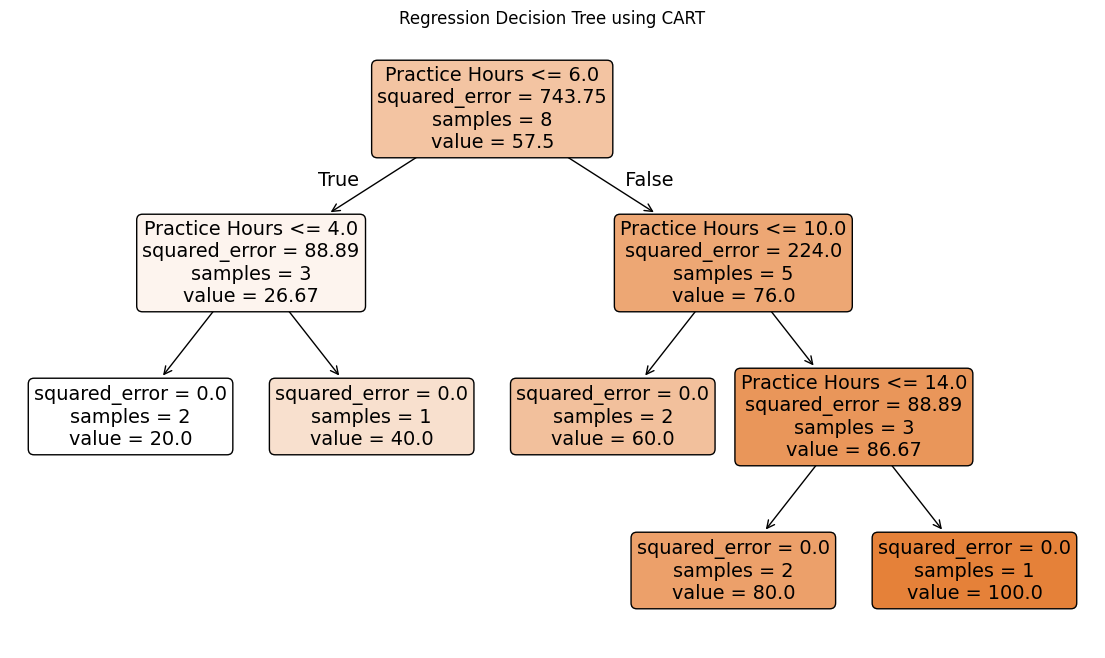

In [15]:

plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=['Practice Hours'],
    filled=True,
    rounded=True,
    precision=2,
    proportion=False
)

plt.title("Regression Decision Tree using CART")
plt.show()


In [17]:

y_pred = model.predict(X)

print("Actual Scores:", y.values)
print("Predicted Scores:", y_pred)

final_mse = mean_squared_error(y, y_pred)

print("Final MSE =", final_mse)


Actual Scores: [ 20  20  40  60  60  80  80 100]
Predicted Scores: [ 20.  20.  40.  60.  60.  80.  80. 100.]
Final MSE = 0.0
